Dataset loaded successfully!
Shape of dataset: (62456, 16)
Columns available: ['row id', 'bgcolor', 'dx', 'dy', 'edgecolor', 'frame', 'name', 'num', 'play', 'player', 'player_num', 'player_obj', 'team', 'x', 'y', 'z']
   row id bgcolor        dx        dy edgecolor  frame  name  num  \
0       0     NaN  0.000000  0.000000       NaN      0   NaN  NaN   
1       1     NaN  0.014062 -0.156108       NaN      1   NaN  NaN   
2       2     NaN  0.012443 -0.102404       NaN      2   NaN  NaN   

                 play  player  player_num  player_obj team          x  \
0  PSG [2]-1 Atalanta       0         NaN         NaN  NaN  75.549926   
1  PSG [2]-1 Atalanta       0         NaN         NaN  NaN  75.563988   
2  PSG [2]-1 Atalanta       0         NaN         NaN  NaN  75.576431   

           y    z  
0  41.461505  0.0  
1  41.305397  0.0  
2  41.202993  0.0  


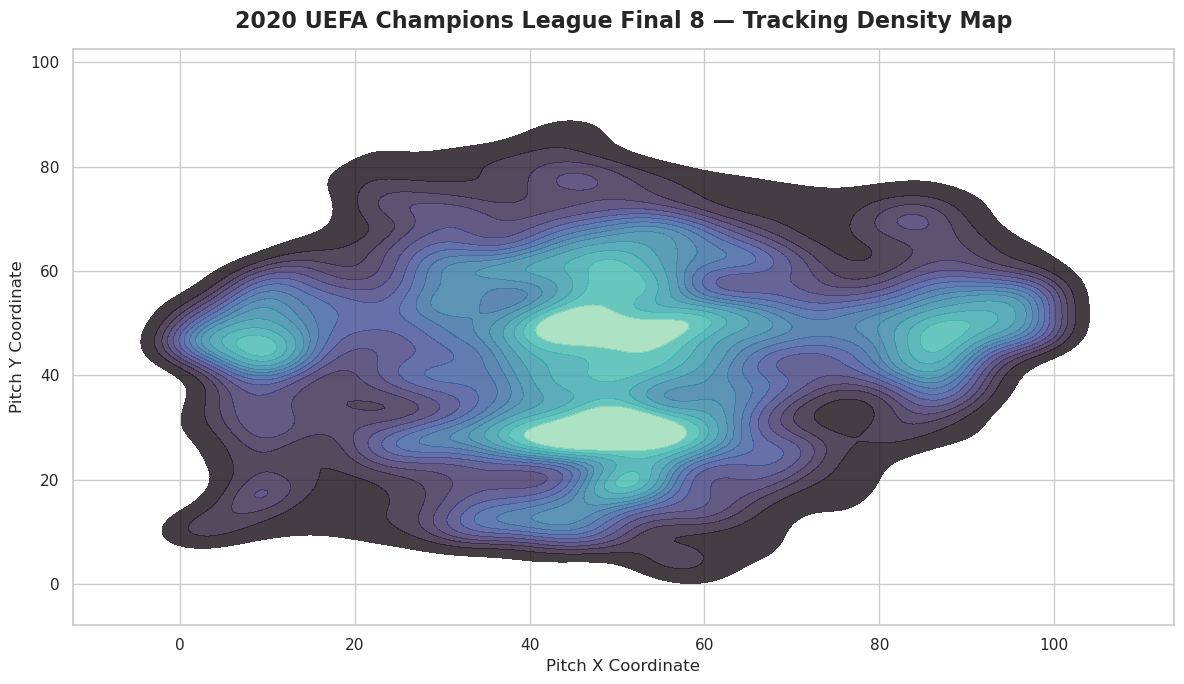

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Load the dataset directly from the GitHub raw URL
url = "https://raw.githubusercontent.com/CJ-Mayes/SportsVizSunday/refs/heads/main/Data/Soccer/Champions%20League/CL2020_final8_tracking.csv"

try:
  df = pd.read_csv(url)
  print("Dataset loaded successfully!")
  print(f"Shape of dataset: {df.shape}")
  print("Columns available:", df.columns.tolist())
  print(df.head(3))
except Exception as e:
  print(f"Error loading dataset: {e}")
  exit()

# 2. Visualization: Spatial Tracking Density Map
# Tracking data typically includes X and Y pitch coordinates.
# If your columns are named differently (e.g., 'X', 'Y', 'position_x'), update them below.
x_col = next(
    (c for c in df.columns if c.lower() in ["x", "coord_x", "position_x"]), None
)
y_col = next(
    (c for c in df.columns if c.lower() in ["y", "coord_y", "position_y"]), None
)

if x_col and y_col:
  plt.figure(figsize=(12, 7))
  sns.set_theme(style="whitegrid")

  # Generate a KDE density plot to show player/ball concentration on the pitch
  sns.kdeplot(
      data=df,
      x=x_col,
      y=y_col,
      fill=True,
      cmap="mako",
      thresh=0.05,
      levels=15,
      alpha=0.8,
  )

  plt.title(
      "2020 UEFA Champions League Final 8 — Tracking Density Map",
      fontsize=16,
      fontweight="bold",
      pad=15,
  )
  plt.xlabel("Pitch X Coordinate", fontsize=12)
  plt.ylabel("Pitch Y Coordinate", fontsize=12)
  plt.tight_layout()
  plt.show()
else:
  # Fallback if coordinate columns have custom names
  print(
      "\nCoordinate columns (X/Y) not automatically detected. Printing value"
      " counts of the first categorical column:"
  )
  cat_col = df.select_dtypes(include=["object"]).columns[0]
  top_counts = df[cat_col].value_counts().head(10).reset_index()
  top_counts.columns = ["Category", "Count"]

  plt.figure(figsize=(12, 6))
  sns.barplot(
      data=top_counts,
      x="Count",
      y="Category",
      hue="Category",
      palette="crest",
      legend=False,
  )
  plt.title(f"Top Categories in {cat_col}", fontsize=14, fontweight="bold")
  plt.xlabel("Count", fontsize=12)
  plt.ylabel(cat_col, fontsize=12)
  plt.tight_layout()
  plt.show()

### Summary of the Visualization

This chart visualizes spatial tracking data from the **2020 UEFA Champions League "Final 8" tournament** (played in Lisbon, Portugal).

Here is what the plot displays:

* **Pitch Positioning & Density:** It maps spatial $(X, Y)$ coordinates onto a soccer pitch layout to show **player movement, ball density, or positional coverage** during the matches.
* **Heatmap / Contour Intensity:** The shaded density contours (KDE plot) highlight high-activity hot spots on the pitch where players or the ball were most frequently located during key phases of play.
* **Tactical Insights:** It allows analysts to observe team spatial structures, pressing zones, defensive block height, or attacking width during the 2020 UCL knockout stages.